# 030 — Avaliar os agregados separadamente

Compara controlo sem agregados, doenças, itens funcionais PL, autocuidado, tarefas e todos os agregados nos mesmos três folds estratificados dos 8.769 registos de treino. Cada pré-processador é ajustado no treino do fold; as épocas do MLP são selecionadas por uma subdivisão desse treino. O controlo 028 é reconstruído segundo a configuração e os resultados guardados (equivalente ao 025: XGBoost + MLP dropout 0,1, mistura 75/25). A fonte executável original do runner 028 não está disponível. O MLP da avaliação fixa usa a mediana das épocas escolhidas nos folds (87 nesta execução), não as 85 épocas históricas do 028; por isso, essa pontuação fixa não é uma reprodução direta do resultado histórico. A limitação e as fórmulas documentadas dos agregados ficam registadas no resultado.

Validação fixa é desenvolvimento, não teste independente. Kaggle fica em branco. Execução sequencial, CPU e uma thread; os checkpoints só são reutilizados após validação de dados, preparação, código, parâmetros e versões.

030: resultados/checkpoints reutilizados após validação de dados, preparação, configuração e versões.


,variant,fold_macro_f1,mean_macro_f1,std_macro_f1,paired_differences_vs_control,mean_paired_difference,std_paired_difference
0,sem_agregados,"[0.4617800815355815, 0.4514670310102532, 0.460...",0.457967,0.005657,"[0.0, 0.0, 0.0]",0.000000,0.000000
1,apenas_doencas,"[0.456713725021186, 0.45006540629976666, 0.449...",0.451948,0.004157,"[-0.005066356514395465, -0.0014016247104865487...",-0.006018,0.005159
2,apenas_itens_funcionais_PL,"[0.4542694977678236, 0.44357057792467386, 0.46...",0.452743,0.008513,"[-0.007510583767757872, -0.007896453085579347,...",-0.005223,0.004300
3,apenas_autocuidado,"[0.45503862035926607, 0.4493172512472715, 0.45...",0.454101,0.004390,"[-0.006741461176315411, -0.002149779762981696,...",-0.003866,0.002506
4,apenas_tarefas,"[0.4607780489287831, 0.45134599111392565, 0.45...",0.454148,0.005765,"[-0.0010020326067983754, -0.000121039896327557...",-0.003819,0.005659
5,todos_os_agregados,"[0.4603744737601453, 0.447296964902934, 0.4486...",0.452110,0.007190,"[-0.0014056077754361906, -0.004170066107319181...",-0.005857,0.005493


Escolhida: sem_agregados | avaliação fixa: {'macro_f1': 0.4562651875364949, 'accuracy': 0.46192430460556316, 'per_class': [{'classe': 0, 'escalão': '15–17 anos', 'F1': 0.8275862068965517, 'recall': 0.8780487804878049, 'support': 41}, {'classe': 1, 'escalão': '18–19 anos', 'F1': 0.36363636363636365, 'recall': 0.29411764705882354, 'support': 34}, {'classe': 2, 'escalão': '20–24 anos', 'F1': 0.5925925925925926, 'recall': 0.6, 'support': 80}, {'classe': 3, 'escalão': '25–29 anos', 'F1': 0.3380281690140845, 'recall': 0.32, 'support': 75}, {'classe': 4, 'escalão': '30–34 anos', 'F1': 0.25806451612903225, 'recall': 0.2222222222222222, 'support': 90}, {'classe': 5, 'escalão': '35–39 anos', 'F1': 0.33935018050541516, 'recall': 0.3643410852713178, 'support': 129}, {'classe': 6, 'escalão': '40–44 anos', 'F1': 0.38857142857142857, 'recall': 0.3953488372093023, 'support': 172}, {'classe': 7, 'escalão': '45–49 anos', 'F1': 0.39274924471299094, 'recall': 0.37572254335260113, 'support': 173}, {'classe

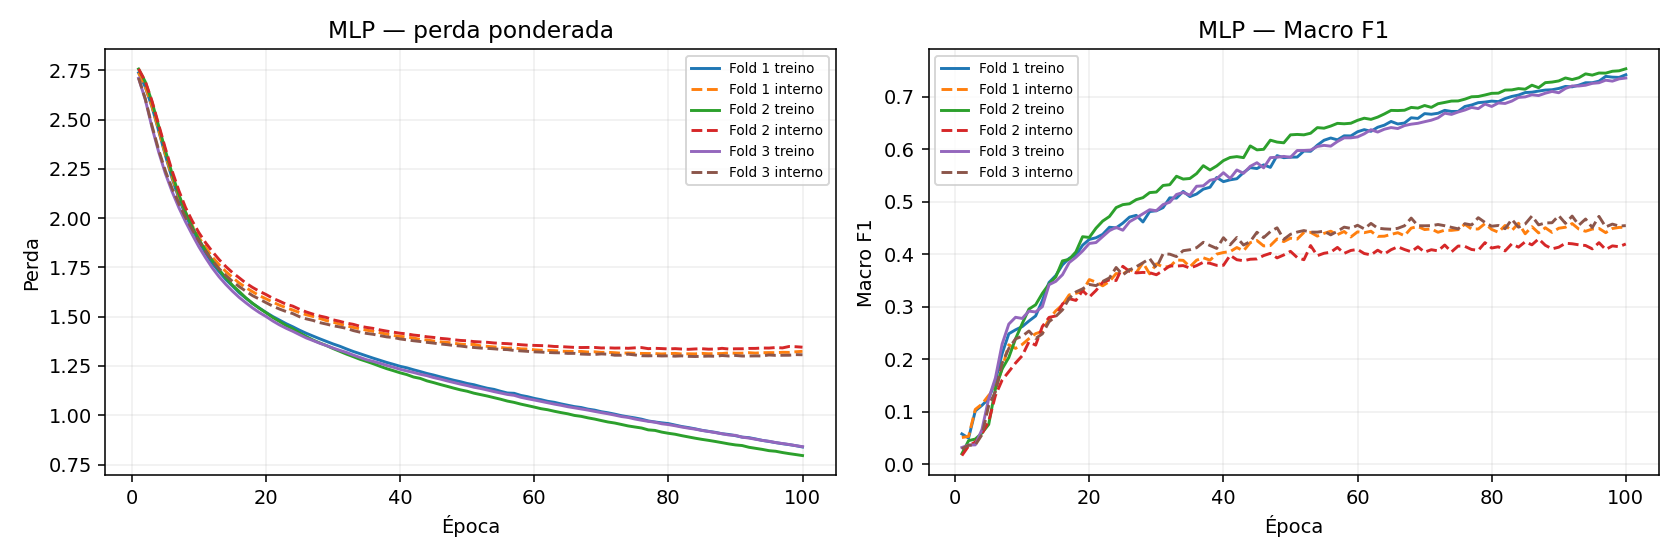

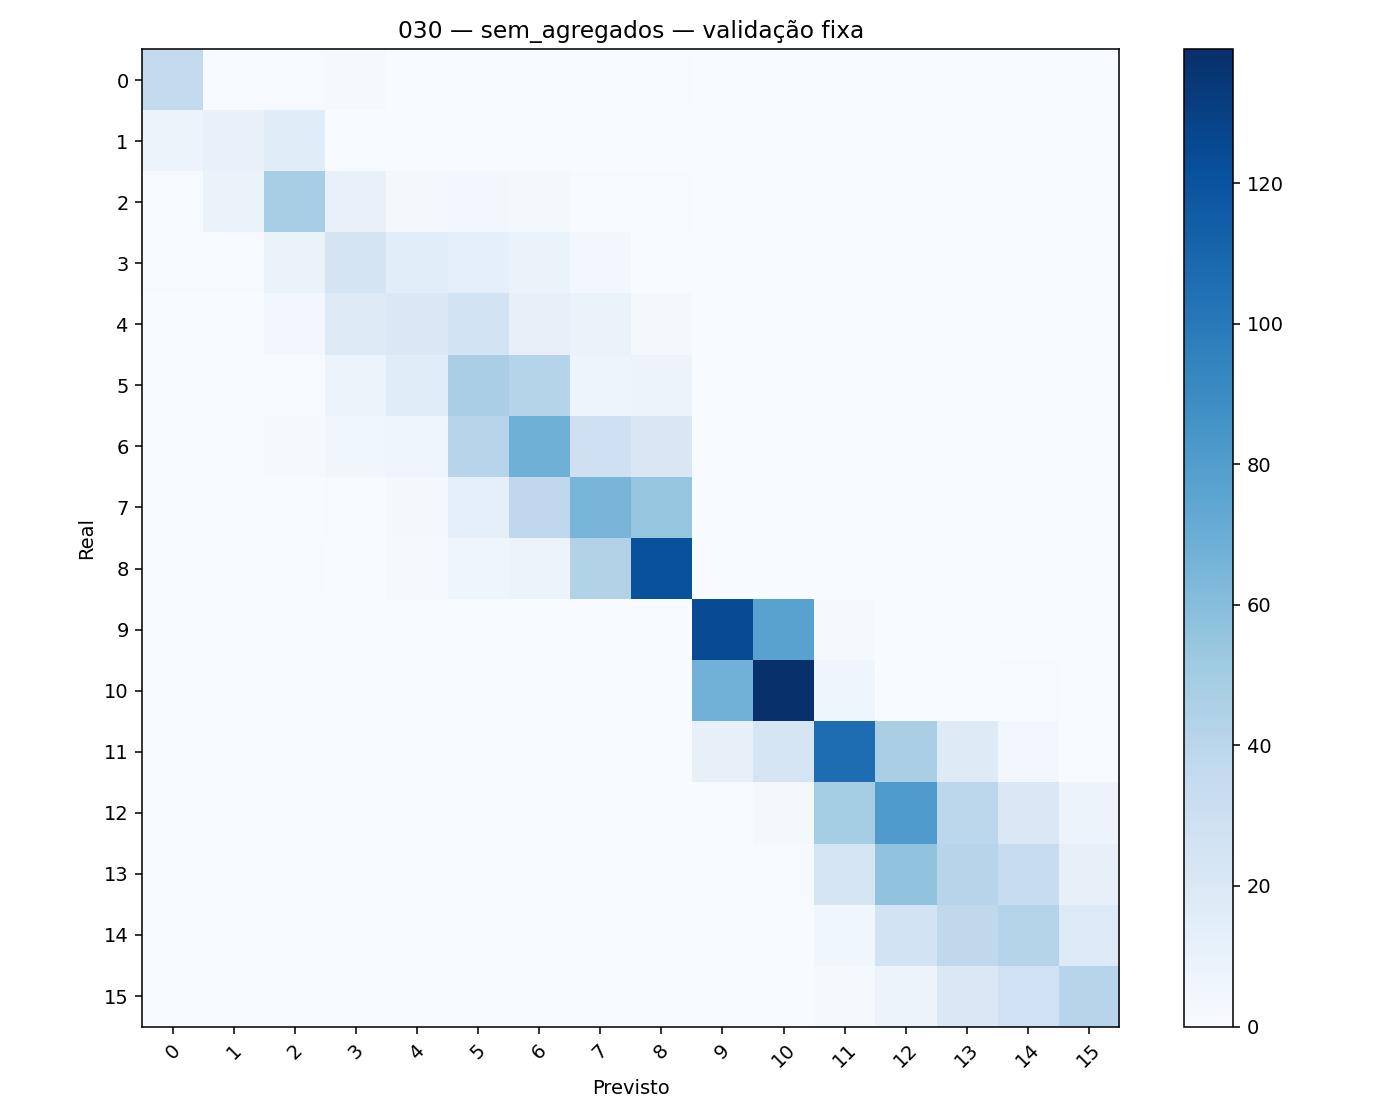

CSV: {'path': None, 'reason': 'O controlo venceu; não foi criado um CSV repetido.', 'differences': {}}
/Users/eduardaferreira/daa-kaggle-2026-2027/reports/experiments_030_032.md


In [1]:
from pathlib import Path
import sys
from IPython.display import display, Image
import pandas as pd

root = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / 'src' / 'experiments_030_032.py').is_file()), None)
if root is None:
    raise FileNotFoundError('Executa este notebook na pasta notebooks/ deste projeto.')
sys.path.insert(0, str(root))
from src.experiments_030_032 import run_030, write_final_report

result = run_030()
display(pd.DataFrame([{k: row[k] for k in ['variant', 'fold_macro_f1', 'mean_macro_f1', 'std_macro_f1', 'paired_differences_vs_control', 'mean_paired_difference', 'std_paired_difference']} for row in result['fold_results']]))
print('Escolhida:', result['selected_variant'], '| avaliação fixa:', result['fixed_validation_once']['validation'])
display(Image(filename=str(root / result['curves'])))
display(Image(filename=str(root / result['confusion_matrix'])))
print('CSV:', result['submission'])
print(write_final_report())

## Conclusão e decisão

- Data: 14/11
- Conclusão: o controlo sem agregados venceu (Macro F1 CV média 0,4580; DP 0,0057). Nenhum grupo melhorou a média. Não foi criado CSV. A avaliação fixa usa 87 épocas, não as 85 históricas do 028.
- Melhorias: recuperar o runner original 028 para uma reprodução fixa integral antes de interpretar diferenças absolutas.